<a href="https://colab.research.google.com/github/MahdiTheGreat/Structured-machine-learning/blob/main/project%201/Structured_ML_Project_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Usage of AI

AI was mainly used to formalize my own arguments and also to generate latex formulas. I also used AI for research and to brush up on some previously learned topics e.g. axioms of Inner product.

In [1]:
!pip install torch
!pip install torch_geometric
!pip install rdkit
!pip install torcheval
!pip install matplotlib
!git clone https://github.com/olsson-group/sml_project1.git

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.2/179.2 kB 6.3 MB/s eta 0:00:00
Cloning into 'sml_project1'...
remote: Enumerating objects: 41, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 41 (delta 14), reused 33 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (41/41), 7.08 KiB | 3.54 MiB/s, done.
Resolving deltas: 100% (14/14), done.


In [2]:
from sml_project1 import metrics, data
from sml_project1.data import ScaffoldSplitter
import torch
import torch_geometric as geom
from torch_geometric.datasets import MoleculeNet
from torch_geometric.data import Data
import matplotlib.pyplot as plt
import random
import numpy as np
import wandb
import time

overall_start_time = time.time()

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
print(f'Using device: {device}')

Using device: cpu


In [3]:
# Filter out graphs with fewer than 2 nodes
def filter_small_graphs(dataset):
    """Remove molecules with fewer than 2 nodes (atoms) and return a new dataset."""
    initial_len = len(dataset)
    # filtered_data_list = [data_obj for data_obj in dataset if data_obj.x.size(0) >= 2]

    # To maintain compatibility with ScaffoldSplitter, we must return a true Dataset object
    # rather than just a list of Data objects. We do this by extracting the valid
    # indices and using PyTorch Geometric's built-in index_select() function to create a Subset.

    valid_indices = [i for i, data_obj in enumerate(dataset) if data_obj.x.size(0) >= 2]
    filtered_dataset = dataset.index_select(valid_indices)
    print(f"Filtered {initial_len - len(filtered_dataset)} molecules with < 2 nodes")
    return filtered_dataset


# Load and filter datasets
esol_raw = MoleculeNet(root='./storage/', name='ESOL')
esol = filter_small_graphs(esol_raw)

bbbp_raw = MoleculeNet(root='./storage/', name='BBBP')
bbbp = filter_small_graphs(bbbp_raw)


# Split datasets with scaffold stratification (Train: 80%, Val: 10%, Test: 10%)
# --- EXPLANATION OF SPLITTING METHOD ---
# We use a ScaffoldSplitter rather than a random split.
# In chemistry, a "scaffold" refers to the core structural framework of a molecule.
# Scaffold splitting groups molecules by their scaffold and completely isolates
# these groups into either Train, Validation, or Test sets.
# This ensures that the Test set contains entirely novel chemical families
# that the model has never seen before. It prevents data leakage and ensures
# that we evaluate the model's true ability to generalize to new drugs,
# rather than just memorizing structures it saw during training.
# ---------------------------------------
seed = 42
torch.manual_seed(seed)
splitter = ScaffoldSplitter()

esol_smiles = [d.smiles for d in esol]
esol_train_idx, esol_val_idx, esol_test_idx = splitter.train_valid_test_split(esol, esol_smiles, frac_train=0.8, frac_valid=0.1, frac_test=0.1, seed=seed)
esol_train_dataset = torch.utils.data.Subset(esol, esol_train_idx)
esol_val_dataset = torch.utils.data.Subset(esol, esol_val_idx)
esol_test_dataset = torch.utils.data.Subset(esol, esol_test_idx)

bbbp_smiles = [d.smiles for d in bbbp]
bbbp_train_idx, bbbp_val_idx, bbbp_test_idx = splitter.train_valid_test_split(bbbp, bbbp_smiles, frac_train=0.8, frac_valid=0.1, frac_test=0.1, seed=seed)
bbbp_train_dataset = torch.utils.data.Subset(bbbp, bbbp_train_idx)
bbbp_val_dataset = torch.utils.data.Subset(bbbp, bbbp_val_idx)
bbbp_test_dataset = torch.utils.data.Subset(bbbp, bbbp_test_idx)

print(f"ESOL: {len(esol)} molecules")
print(f"  Train: {len(esol_train_dataset)}, Val: {len(esol_val_dataset)}, Test: {len(esol_test_dataset)}")
print(f"BBBP: {len(bbbp)} molecules")
print(f"  Train: {len(bbbp_train_dataset)}, Val: {len(bbbp_val_dataset)}, Test: {len(bbbp_test_dataset)}")

def print_data_info(dataset, name, visualize=False):
    print("\n" + "="*50)
    print(f"Dataset: {name}")
    print("="*50)
    print(f"Number of graphs: {len(dataset)}")
    print(f"Number of node features: {dataset.num_node_features}")
    print(f"Number of edge features: {dataset.num_edge_features}")

    if len(dataset) > 0:
        graph = dataset[0]
        print(f"Example Graph 0: {graph}")
        print(f"Example Node Features (x): \n{graph.x[:5]} ... (truncated)")
        print(f"Example Target (y): {graph.y}")

        if visualize:
            from torch_geometric.utils import to_networkx
            import networkx as nx
            import matplotlib.pyplot as plt

            print(f"Visualizing Graph 0 from {name}...")
            G = to_networkx(graph, to_undirected=True)
            nx.draw(G, with_labels=True, node_color='lightblue', edge_color='gray')
            plt.show()
    print("="*50 + "\n")

print_data_info(esol, "ESOL", visualize=False)
print_data_info(bbbp, "BBBP", visualize=False)

Processing...
Done!


Filtered 1 molecules with < 2 nodes


Processing...
/usr/local/lib/python3.13/dist-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 'O=N([O-])C1=C(CN=C1NCCSCc2ncccc2)Cc3ccccc3' since it resulted in zero atoms
  self.process()
/usr/local/lib/python3.13/dist-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 'c1(nc(NC(N)=[NH2])sc1)CSCCNC(=[NH]C#N)NC' since it resulted in zero atoms
  self.process()
/usr/local/lib/python3.13/dist-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 'Cc1nc(sc1)\[NH]=C(\N)N' since it resulted in zero atoms
  self.process()
/usr/local/lib/python3.13/dist-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 's1cc(CSCCN\C(NC)=[NH]\C#N)nc1\[NH]=C(\N)N' since it resulted in zero atoms
  self.process()
/usr/local/lib/python3.13/dist-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 'c1c(c(ncc1)CSCCN\C(=[NH]\C#N)NCC)Br' since it resulted in zero atoms
  self.process()
/usr/l

Filtered 0 molecules with < 2 nodes
ESOL: 1127 molecules
  Train: 903, Val: 112, Test: 112
BBBP: 2039 molecules
  Train: 1633, Val: 203, Test: 203

Dataset: ESOL
Number of graphs: 1127
Number of node features: 9
Number of edge features: 3
Example Graph 0: Data(x=[32, 9], edge_index=[2, 68], edge_attr=[68, 3], smiles='OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O ', y=[1, 1])
Example Node Features (x): 
tensor([[8, 0, 2, 5, 1, 0, 4, 0, 0],
        [6, 0, 4, 5, 2, 0, 4, 0, 0],
        [6, 0, 4, 5, 1, 0, 4, 0, 1],
        [8, 0, 2, 5, 0, 0, 4, 0, 1],
        [6, 0, 4, 5, 1, 0, 4, 0, 1]]) ... (truncated)
Example Target (y): tensor([[-0.7700]])


Dataset: BBBP
Number of graphs: 2039
Number of node features: 9
Number of edge features: 3
Example Graph 0: Data(x=[20, 9], edge_index=[2, 40], edge_attr=[40, 3], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1])
Example Node Features (x): 
tensor([[17,  0,  0,  5,  0,  1,  4,  0,  0],
        [ 6,  0,  4,  5,  3,  0,  4,  0,  0],
      

In [14]:
from torch_geometric.nn import GraphConv, GATConv, global_mean_pool
import torch.nn as nn

class MolecularGraphNet(torch.nn.Module):
  # This is the parent class for both the regression and classification task

  def __init__(self, embedding, net, onehot_sizes, name="MolecularGraphNet"):
    super().__init__()
    self.embedding = embedding
    self.onehot_sizes = onehot_sizes  # List of num_classes for features 1-8
    self.net = net
    self.name = name
    self.setup_optimizer()

  def training_step(self, loss):
    loss.backward()
    self.optimizer.step()
    self.optimizer.zero_grad()

  def setup_optimizer(self):
    self.optimizer = torch.optim.Adam(self.parameters(), lr=0.001)

  def forward(self, batch):

    # Implement in children
    # We Setup the forward pass of the model for a classification task
    # this includes embedding the input data, applying the graph network,
    # pooling the results, and predicting an output.
    # where batch.x denotes the node features,
    # batch.batch denotes which graph each node belongs to

    # HINT: Pooling can be done using
    #     x = geom.nn.global_mean_pool(batch.x, batch.batch)
    # where batch.x denotes the node features, and batch.batch denotes which
    # graph each node belongs to

    # TODO: Setup the forward pass of the model for a classification task, this
    # includes embedding the input data, applying the graph network, pooling
    # the results, and predicting an output.

    #x = batch.x.to(torch.float32)  # prevent a type mismatch
    #print('batch is ', batch)
    x=batch.x
    atomic_embedded = self.embedding(x[:, 0])  # [num_nodes, 32]
    # Features 1-8: One-hot encode
    onehot_features = []
    for i, num_classes in enumerate(self.onehot_sizes, start=1):
     #print(f"Feature index: {i}, num_classes: {num_classes}")
     #print(f"Values for feature {i}: {x[:, i]}")
     # Add 1 to num_classes because values are 0-indexed and can go up to num_classes - 1
     # We cannot cast `batch.x` to float32 early because it contains discrete
     # categorical integers (like atomic numbers). Both `nn.Embedding` and
     # `nn.functional.one_hot` strictly require integer indices. We cast the
     # features to float32 *after* encoding them (see line 190).

     onehot = nn.functional.one_hot(x[:, i], num_classes=num_classes + 1).float()
     onehot_features.append(onehot)

        # Concatenate: embedded atomic number + all one-hot features
    x = torch.cat([atomic_embedded] + onehot_features, dim=1)

    #print("x shape after embedding is ",x.shape)

    # 3. Apply GNN layers
    x = self.net(x, batch.edge_index, batch.batch)
    # 4. Pool graph-level representation
    #print("net out shape: ",x.shape)
    x = geom.nn.global_mean_pool(x, batch.batch)
    return x.squeeze()

  def loss(self, y, y_hat):
    # Implement in children
    raise NotImplementedError

  def evaluate(self, y, y_hat):
    # Implement in children
    raise NotImplementedError


from torch_geometric.nn import GraphConv, GATConv, global_mean_pool
import torch.nn as nn

class MolecularGraphClassification(MolecularGraphNet):
  def __init__(self, embedding, net,onehot_sizes, name="MolecularGraphClassification"):
    super().__init__(embedding, net,onehot_sizes, name=name)
    self.sigmoid = nn.Sigmoid()
    self.bce_loss = nn.BCELoss() # Instantiate BCELoss here

  def forward(self, batch):
   return self.sigmoid(super().forward(batch))

  def loss(self, y, y_hat):
    # Setup the appropriate loss for training a classification model.
    return self.bce_loss(y_hat, y.squeeze().float()) # Call the BCELoss instance and pass y_hat and y

  def evaluate(self, y, y_hat):
    roc_auc = metrics.get_auc_roc(y, y_hat)
    return {"roc_auc": roc_auc}

class MolecularGraphRegression(MolecularGraphNet):
 def __init__(self, embedding, net,onehot_sizes, name="MolecularGraphRegression"):
   super().__init__(embedding, net,onehot_sizes, name=name)

 def forward(self, batch):
   return super().forward(batch)

 def loss(self, y, y_hat):
   return torch.nn.functional.mse_loss(y.squeeze(), y_hat)

 def evaluate(self, y, y_hat):
   pcc = metrics.get_pearson_corr(y, y_hat)[0]
   rmse = metrics.get_rmse(y, y_hat)
   return {"pcc": pcc, "rmse": rmse}

class DeepSet(torch.nn.Module):
    def __init__(self, in_features, hidden_features, out_features=1, num_layers=2):
        super().__init__()
        self.num_layers = num_layers
        self.layers = nn.ModuleList()

        # Input layer
        self.layers.append(nn.Linear(in_features, hidden_features))
        self.layers.append(nn.ReLU())

        # Hidden layers
        for _ in range(num_layers - 2):
            self.layers.append(nn.Linear(hidden_features, hidden_features))
            self.layers.append(nn.ReLU())

        # Output layer
        self.layers.append(nn.Linear(hidden_features, out_features))


    def forward(self, x, edge_index, batch):
        out = x
        for layer in self.layers:
            if isinstance(layer, nn.Linear):
              out = layer(out)
            else: # Assuming ReLU
              out = layer(out)
        return out

from torch_geometric.nn import GCNConv, global_mean_pool
import torch.nn as nn

class GCN(torch.nn.Module):
# We use 1 Message Passing Layer (the GCNConv layer) followed by a ReLU activation, and then a final Linear layer to make the prediction.
# While this might sound "shallow", shallow networks are actually a massive advantage for GCNs.
# GCNs suffer heavily from a well-documented mathematical flaw called "Oversmoothing".
# If you use too many GCN layers (e.g., 3 or 4+), the features of every atom in the molecule become averaged out and mathematically identical,
# destroying the model's predictive power. shallow prevents oversmoothing while still leveraging the layer-wise propagation rule from Kipf & Welling.
    def __init__(self,in_features, hidden_features, out_features=1, num_layers=2):
        super().__init__()
        self.num_layers = num_layers
        self.layers = nn.ModuleList()

        # Input layer
        self.layers.append(GCNConv(in_features, hidden_features))

        # Hidden layers
        for _ in range(num_layers - 2):
            self.layers.append(GCNConv(hidden_features, hidden_features))

        # Output layer
        self.layers.append(nn.Linear(hidden_features, out_features))

    def forward(self, x, edge_index, batch):
        # Apply GCN layers with ReLU
        for i in range(len(self.layers) - 1):
            x = self.layers[i](x, edge_index)
            x = torch.relu(x)

        # Apply final linear layer
        x = self.layers[-1](x)
        return x


class GAT(torch.nn.Module):
# We use 2 Message Passing Layers. The first layer is a Multi-Head Attention layer (heads=4) followed by an ELU activation.
# The second layer is a consolidating GAT layer (heads=1) followed by a ReLU, and then the final Linear prediction layer.
# The 2-layer structure (multi-head followed by single-head) mimics the architectural design proposed in the foundational GAT paper.

    def __init__(self, in_features, hidden_features, out_features=1, num_layers=2, heads=4):
        super().__init__()
        self.num_layers = num_layers
        self.heads = heads # Number of attention heads for the first layer
        self.layers = nn.ModuleList()

        # First GAT layer (with multiple heads)
        self.layers.append(GATConv(in_features, hidden_features, heads=self.heads, concat=True))
        self.layers.append(nn.ELU()) # Activation after first GAT layer

        # Hidden GAT layers (collapsing heads if needed, or keeping multi-head)
        # For simplicity here, let's add more multi-head GAT layers if num_layers > 2
        # A more complex implementation might alternate between multi-head and single-head
        for _ in range(num_layers - 2):
             self.layers.append(GATConv(hidden_features * self.heads, hidden_features, heads=self.heads, concat=True))
             self.layers.append(nn.ELU())


        # Final layer (either GAT or Linear). Let's use a final GAT layer that collapses heads
        self.layers.append(GATConv(hidden_features * self.heads, hidden_features, heads=1, concat=False))
        self.layers.append(nn.ReLU()) # Activation after final GAT layer


        # Final linear layer for prediction
        self.layers.append(nn.Linear(hidden_features, out_features))


    def forward(self, x, edge_index, batch):
        out = x
        # Apply GAT and activation layers
        for layer in self.layers[:-1]: # Apply all layers except the final linear layer
             if isinstance(layer, GATConv):
                out = layer(out, edge_index)
             else: # Activation layer
                out = layer(out)

        # Apply final linear layer
        out = self.layers[-1](out)
        return out

# TODO: Present results for the regression task and compare model types. This
# can be in the form of tables or graphs or however you see fit

def plot_results(results, model_name):
    epochs = range(1, len(results['train_loss']) + 1)
    metrics_to_plot = list(results['train_metrics'][0].keys())
    num_metrics = len(metrics_to_plot)
    fig, axes = plt.subplots(1, num_metrics + 1, figsize=(6 * (num_metrics + 1), 5))

    # Plot Loss
    axes[0].plot(epochs, results['train_loss'], label='Train Loss')
    axes[0].plot(epochs, results['val_loss'], label='Validation Loss')
    axes[0].set_title(f'{model_name} - Loss over Epochs')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True)

    # Plot Metrics
    for i, metric_name in enumerate(metrics_to_plot):
        train_metric_values = [m[metric_name] for m in results['train_metrics']]
        val_metric_values = [m[metric_name] for m in results['val_metrics']]
        axes[i+1].plot(epochs, train_metric_values, label=f'Train {metric_name.upper()}')
        axes[i+1].plot(epochs, val_metric_values, label=f'Validation {metric_name.upper()}')
        axes[i+1].set_title(f'{model_name} - {metric_name.upper()} over Epochs')
        axes[i+1].set_xlabel('Epoch')
        axes[i+1].set_ylabel(metric_name.upper())
        axes[i+1].legend()
        axes[i+1].grid(True)


    plt.tight_layout()
    plt.show()

def train(model, train_dataset, batch_size, val_dataset, test_dataset, n_epochs, val_factor=2, use_wandb=False, patience=15):
    import copy
    print(f"Training {model.name} with {batch_size} batch size for {n_epochs} epochs (Early Stopping Patience: {patience})...")

    if use_wandb:
     # Generate a dynamic project name
     name = f"{model.name}_epochs{n_epochs}_batch{batch_size}_layers{model.net.num_layers}"
     # Initialize a wandb run
     wandb.init(project=model.name, name=name)

    train_dataloader = geom.loader.DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True
    )

    val_dataloader = geom.loader.DataLoader(
        val_dataset, batch_size=batch_size*val_factor, drop_last=False # Fixed ZeroDivisionError
    )

    train_losses = []
    val_losses = []
    train_metrics = []
    val_metrics = []

    best_val_loss = float('inf')
    best_model_weights = None
    patience_counter = 0

    for epoch in range(n_epochs):
        # === TRAINING ===
        model.train()
        epoch_train_loss = 0
        all_train_y = []
        all_train_y_hat = []

        for i, batch in enumerate(train_dataloader):
            batch = batch.to(device)

            # Forward pass
            y_hat = model(batch)

            if epoch == 0 and i == 0:
                print(f"\nArchitecture of {model.name} after first forward pass:")
                print(model)
                print("\n")

            # Calculate loss
            loss = model.loss(batch.y, y_hat)

            # Backward pass
            model.training_step(loss)

            epoch_train_loss += loss.item()

            # Safely move predictions to CPU RAM to prevent GPU Out-of-Memory leaks
            # (sklearn metrics require CPU anyway). .view(-1) flattens the tensor
            # to prevent torch.cat crashes if a batch only has 1 molecule left.
            all_train_y.append(batch.y.cpu().view(-1))
            all_train_y_hat.append(y_hat.detach().cpu().view(-1))

        # Calculate epoch train metrics properly
        all_train_y = torch.cat(all_train_y, dim=0)
        all_train_y_hat = torch.cat(all_train_y_hat, dim=0)
        try:
            avg_train_metrics = model.evaluate(all_train_y, all_train_y_hat)
        except Exception:
            avg_train_metrics = {"error": 0.0}

        # === VALIDATION ===
        model.eval()
        epoch_val_loss = 0
        all_val_y = []
        all_val_y_hat = []

        with torch.no_grad():
            for val_batch in val_dataloader:
                val_batch = val_batch.to(device)

                # Forward pass
                y_hat = model(val_batch)

                # Calculate loss
                loss = model.loss(val_batch.y, y_hat)
                epoch_val_loss += loss.item()

                # Offload to CPU to prevent memory leaks and flatten to 1D
                all_val_y.append(val_batch.y.cpu().view(-1))
                all_val_y_hat.append(y_hat.cpu().view(-1))

        # Calculate epoch val metrics properly
        all_val_y = torch.cat(all_val_y, dim=0)
        all_val_y_hat = torch.cat(all_val_y_hat, dim=0)
        try:
            avg_val_metrics = model.evaluate(all_val_y, all_val_y_hat)
        except Exception:
            avg_val_metrics = {"error": 0.0}

        # Average metrics
        avg_train_loss = epoch_train_loss / max(1, len(train_dataloader))
        avg_val_loss = epoch_val_loss / max(1, len(val_dataloader))


        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        train_metrics.append(avg_train_metrics)
        val_metrics.append(avg_val_metrics)
        if (epoch + 1) % 5 == 0:
         print(f"Epoch {epoch+1}/{n_epochs}")
         print(f"  Train - Loss: {avg_train_loss:.4f}, {', '.join([f'{k}: {v:.4f}' for k, v in avg_train_metrics.items()])}")
         print(f"  Val   - Loss: {avg_val_loss:.4f}, {', '.join([f'{k}: {v:.4f}' for k, v in avg_val_metrics.items()])}")

        if use_wandb:
         # Log metrics to wandb
         wandb.log({
             "epoch": epoch + 1,
             "train_loss": avg_train_loss,
             "val_loss": avg_val_loss,
             **{f"train_{k}": v for k, v in avg_train_metrics.items()},
             **{f"val_{k}": v for k, v in avg_val_metrics.items()}
         })

        # Early Stopping Logic
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_model_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch+1}!")
            break

    # Restore the best model weights before testing
    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)

    # === TEST EVALUATION ===
    test_dataloader = geom.loader.DataLoader(test_dataset, batch_size=batch_size*val_factor, drop_last=False)
    model.eval()
    all_test_y = []
    all_test_y_hat = []

    with torch.no_grad():
        for test_batch in test_dataloader:
            test_batch = test_batch.to(device)
            y_hat = model(test_batch)
            # Offload to CPU to prevent memory leaks and flatten to 1D
            all_test_y.append(test_batch.y.cpu().view(-1))
            all_test_y_hat.append(y_hat.cpu().view(-1))

    all_test_y = torch.cat(all_test_y, dim=0)
    all_test_y_hat = torch.cat(all_test_y_hat, dim=0)
    final_test_metrics = model.evaluate(all_test_y, all_test_y_hat)

    print(f"  Final Test Metrics: {', '.join([f'{k}: {v:.4f}' for k, v in final_test_metrics.items()])}")


    hist= {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "train_metrics": train_metrics,
        "val_metrics": val_metrics,
        "test_metrics": final_test_metrics
    }

    plot_results(hist, model.name)

    # Finish the wandb run
    if use_wandb:
        wandb.finish()

    return hist

def get_max_values(dataset):
 #print("\nDetermining embedding sizes...")
 max_vals = []
 for i in range(9):
     # Get max value for the current feature across all data objects in the dataset
     max_val = int(max([data.x[:, i].max().item() for data in dataset]))
     #print(f"Feature {i}: max value = {max_val}, need embedding size = {max_val + 1}")
     max_vals.append(max_val)
 return max_vals



from collections import defaultdict

def run_experiment(model_class, model_kwargs, train_ds, val_ds, test_ds, batch_size, n_epochs, repeat_factor=3):
    print(f"\n{'='*50}")
    print(f"Running Experiment: {model_kwargs['name']} ({repeat_factor} replicates)")
    print(f"{'='*50}")

    all_test_metrics = defaultdict(list)
    start_time = time.time()

    for i in range(repeat_factor):
        print(f"\n--- Replicate {i+1}/{repeat_factor} ---")
        # Re-initialize model to get random weights for each replicate
        model = model_class(**model_kwargs).to(device)
        hist = train(model, train_ds, batch_size, val_ds, test_ds, n_epochs)

        for k, v in hist['test_metrics'].items():
            all_test_metrics[k].append(v)

    end_time = time.time()
    print(f"\n>>> FINAL AGGREGATED RESULTS FOR {model_kwargs['name']} <<<")

    print(f"Total time taken: {end_time - start_time:.2f} seconds")

    final_metrics_summary = {}
    for k, v_list in all_test_metrics.items():
        mean_val = np.mean(v_list)
        std_val = np.std(v_list)
        print(f"  Test {k.upper()}: {mean_val:.4f} ± {std_val:.4f}")
        final_metrics_summary[k] = (mean_val, std_val)

    return final_metrics_summary

repeat_factor=3

in features: 59

Running Experiment: DeepSet Regression (3 replicates)

--- Replicate 1/3 ---
Training DeepSet Regression with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=59, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)


Epoch 5/200
  Train - Loss: 3.2380, pcc: 0.3972, rmse: 1.8042
  Val   - Loss: 7.7319, pcc: 0.7623, rmse: 2.6744
Epoch 10/200
  Train - Loss: 3.0778, pcc: 0.4448, rmse: 1.7424
  Val   - Loss: 6.3981, pcc: 0.7766, rmse: 2.4397
Epoch 15/200
  Train - Loss: 2.8441, pcc: 0.4856, rmse: 1.6964
  Val   - Loss: 5.9965, pcc: 0.7681, rmse: 2.3621
Epoch 20/200
  Train - Loss: 2.5969, pcc: 0.5542, rmse: 1.6239
  Val   - Loss: 5.3547, pcc: 0.7518, rmse: 2.2353
Epoch 25/200
  Train - Loss: 2.4341, pcc

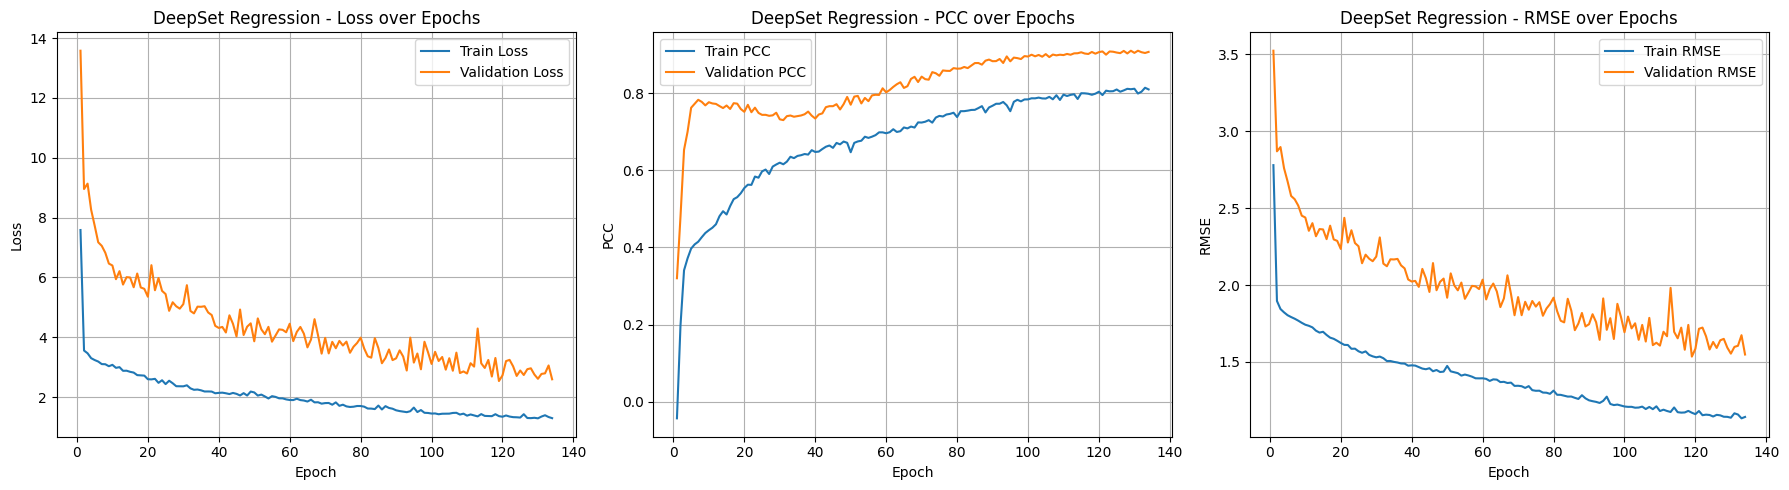


--- Replicate 2/3 ---
Training DeepSet Regression with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=59, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)


Epoch 5/200
  Train - Loss: 1.3057, pcc: 0.8087, rmse: 1.1478
  Val   - Loss: 3.3875, pcc: 0.9110, rmse: 1.7636
Epoch 10/200
  Train - Loss: 1.2911, pcc: 0.8105, rmse: 1.1396
  Val   - Loss: 2.9360, pcc: 0.9024, rmse: 1.6422
Epoch 15/200
  Train - Loss: 1.2853, pcc: 0.8093, rmse: 1.1400
  Val   - Loss: 2.4115, pcc: 0.9055, rmse: 1.4979
Epoch 20/200
  Train - Loss: 1.2599, pcc: 0.8116, rmse: 1.1354
  Val   - Loss: 3.4173, pcc: 0.9095, rmse: 1.7701
Epoch 25/200
  Train - Loss: 1.2428, pcc: 0.8180, rmse: 1.1198
  Val   - Loss: 2.8134, pcc: 0.9042, rmse: 1.609

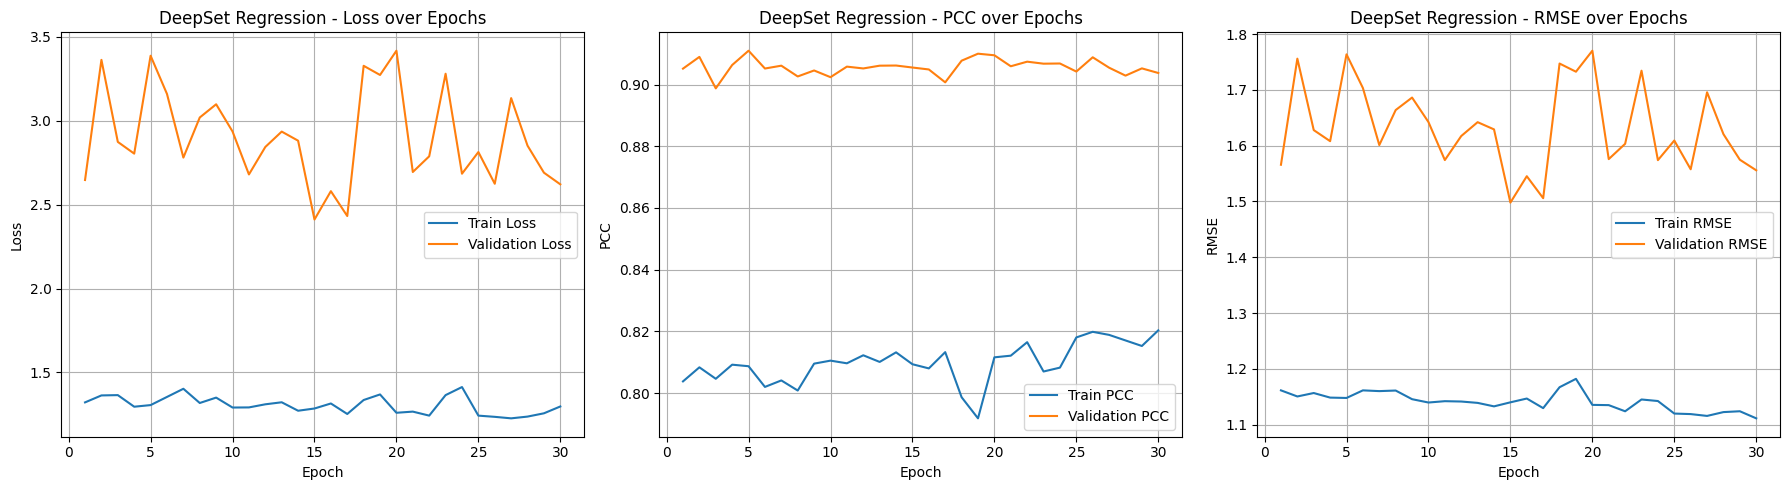


--- Replicate 3/3 ---
Training DeepSet Regression with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=59, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)


Epoch 5/200
  Train - Loss: 1.2637, pcc: 0.8130, rmse: 1.1329
  Val   - Loss: 3.2295, pcc: 0.9082, rmse: 1.7218
Epoch 10/200
  Train - Loss: 1.2410, pcc: 0.8154, rmse: 1.1253
  Val   - Loss: 2.6340, pcc: 0.9072, rmse: 1.5591
Epoch 15/200
  Train - Loss: 1.3112, pcc: 0.8046, rmse: 1.1512
  Val   - Loss: 2.4542, pcc: 0.9054, rmse: 1.5086
Epoch 20/200
  Train - Loss: 1.2215, pcc: 0.8221, rmse: 1.1078
  Val   - Loss: 3.2196, pcc: 0.9045, rmse: 1.7184
Epoch 25/200
  Train - Loss: 1.1927, pcc: 0.8227, rmse: 1.1022
  Val   - Loss: 2.5140, pcc: 0.9018, rmse: 1.524

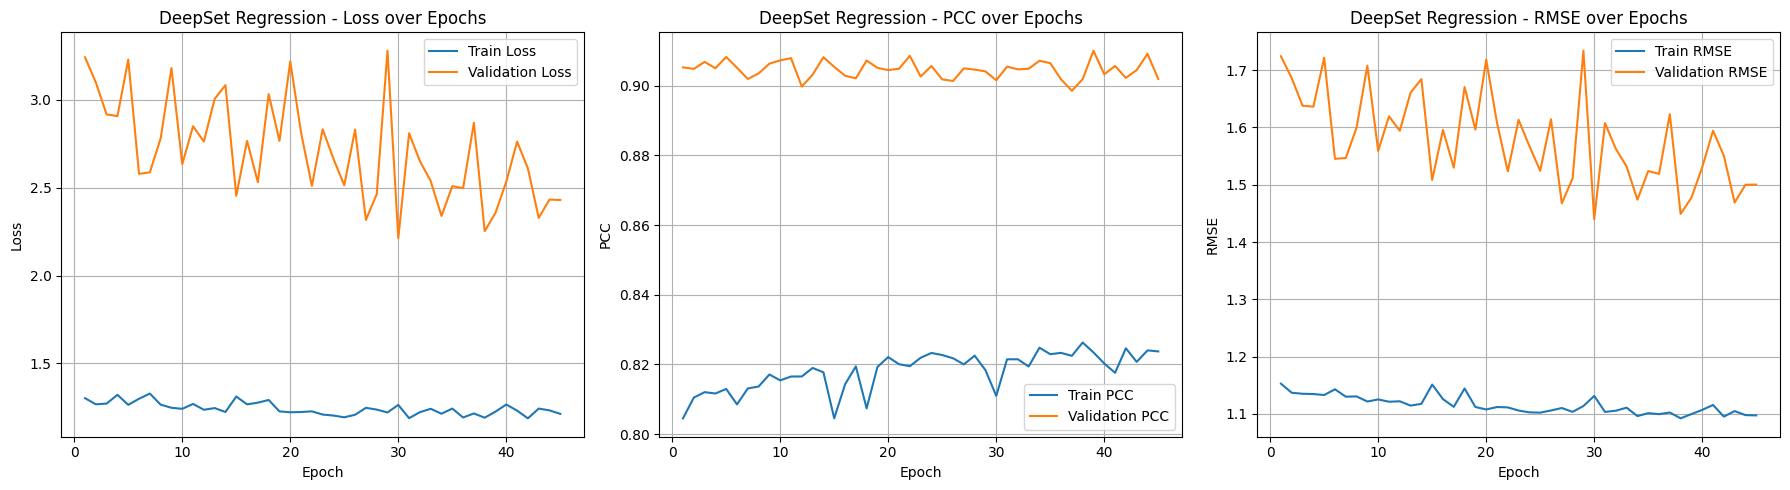


>>> FINAL AGGREGATED RESULTS FOR DeepSet Regression <<<
Total time taken: 39.53 seconds
  Test PCC: 0.7639 ± 0.0090
  Test RMSE: 1.3630 ± 0.0221

Running Experiment: GCN Regression (3 replicates)

--- Replicate 1/3 ---
Training GCN Regression with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GCN Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(59, 64)
      (1): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)


Epoch 5/200
  Train - Loss: 3.1886, pcc: 0.4144, rmse: 1.7871
  Val   - Loss: 7.5314, pcc: 0.7113, rmse: 2.6394
Epoch 10/200
  Train - Loss: 2.8145, pcc: 0.4929, rmse: 1.6925
  Val   - Loss: 5.8096, pcc: 0.7679, rmse: 2.3296
Epoch 15/200
  Train - Loss: 2.6337, pcc: 0.5482, rmse: 1.6319
  Val   - Loss: 5.5192, pcc: 0.7439, rmse: 2.2730
Epoch 20/200
  Train - Loss: 2.4547, pcc: 0.5895, rmse: 1.5725
  Val   - Loss: 4.8674, pcc: 

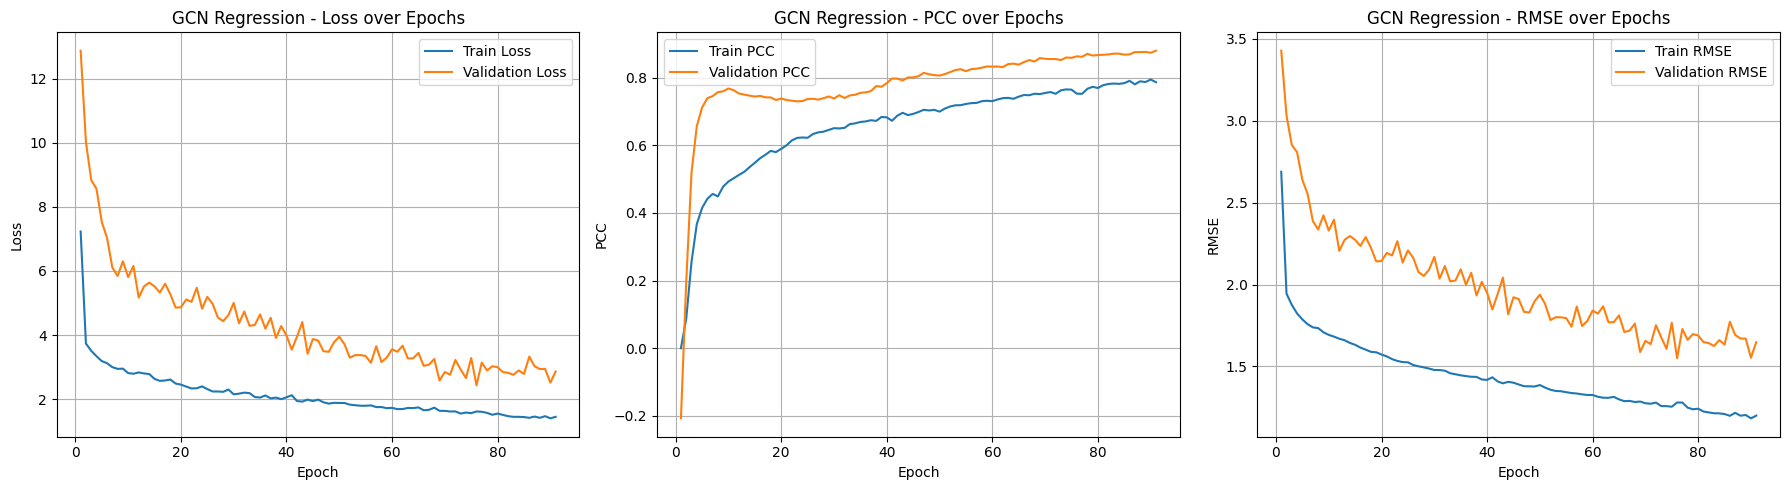


--- Replicate 2/3 ---
Training GCN Regression with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GCN Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(59, 64)
      (1): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)


Epoch 5/200
  Train - Loss: 1.5178, pcc: 0.7752, rmse: 1.2302
  Val   - Loss: 2.7603, pcc: 0.8697, rmse: 1.6257
Epoch 10/200
  Train - Loss: 1.4180, pcc: 0.7898, rmse: 1.1994
  Val   - Loss: 2.9938, pcc: 0.8719, rmse: 1.6850
Epoch 15/200
  Train - Loss: 1.3766, pcc: 0.7968, rmse: 1.1808
  Val   - Loss: 2.4942, pcc: 0.8787, rmse: 1.5476
Epoch 20/200
  Train - Loss: 1.3935, pcc: 0.8052, rmse: 1.1595
  Val   - Loss: 2.6922, pcc: 0.8789, rmse: 1.5981
Epoch 25/200
  Train - Loss: 1.2953, pcc: 0.8155, rmse: 1.1362
  Val   - Loss: 2.8278, pcc: 0.8886, rmse: 1.6317
Epoch 30/200
  Train - Loss: 1.2251, pcc: 0.8198, rmse: 1.1172


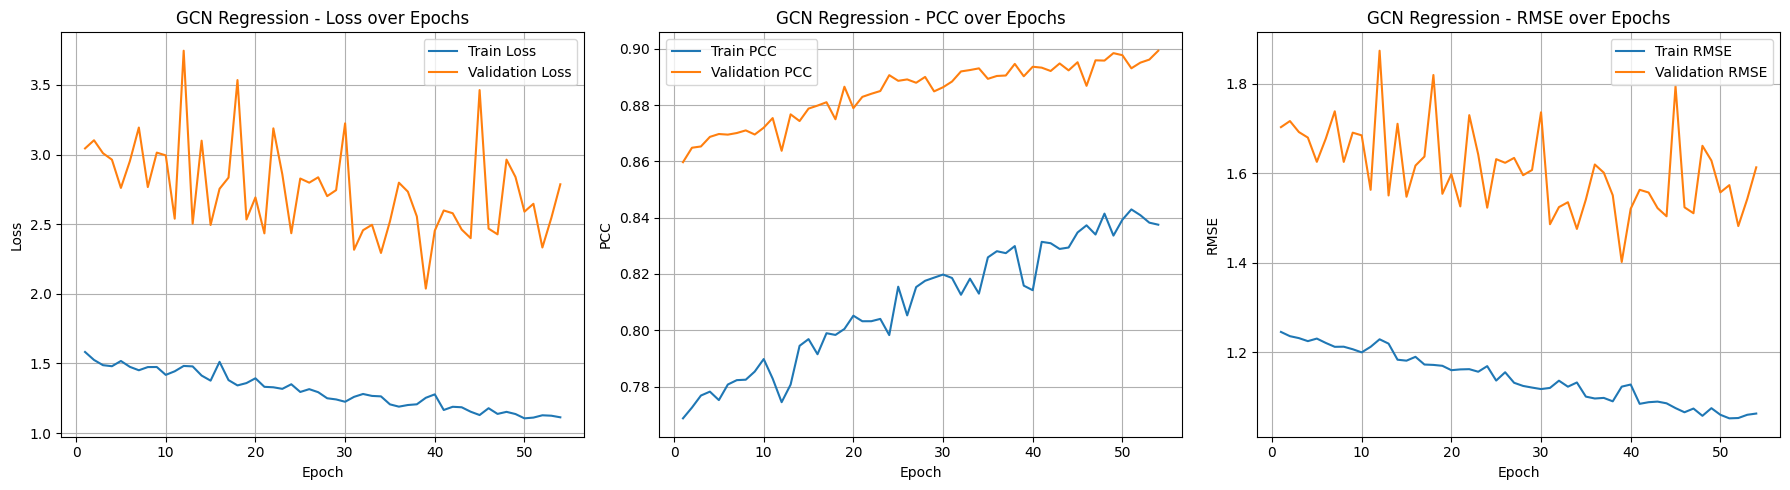


--- Replicate 3/3 ---
Training GCN Regression with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GCN Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(59, 64)
      (1): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)


Epoch 5/200
  Train - Loss: 1.1877, pcc: 0.8266, rmse: 1.0945
  Val   - Loss: 2.3624, pcc: 0.8974, rmse: 1.4926
Epoch 10/200
  Train - Loss: 1.1045, pcc: 0.8406, rmse: 1.0544
  Val   - Loss: 2.8770, pcc: 0.8947, rmse: 1.6382
Epoch 15/200
  Train - Loss: 1.0870, pcc: 0.8419, rmse: 1.0529
  Val   - Loss: 2.7864, pcc: 0.8960, rmse: 1.6138
Epoch 20/200
  Train - Loss: 1.0749, pcc: 0.8471, rmse: 1.0365
  Val   - Loss: 2.4170, pcc: 0.8927, rmse: 1.5062
Early stopping triggered at epoch 21!
  Final Test Metrics: pcc: 0.7176, rmse: 1.4769


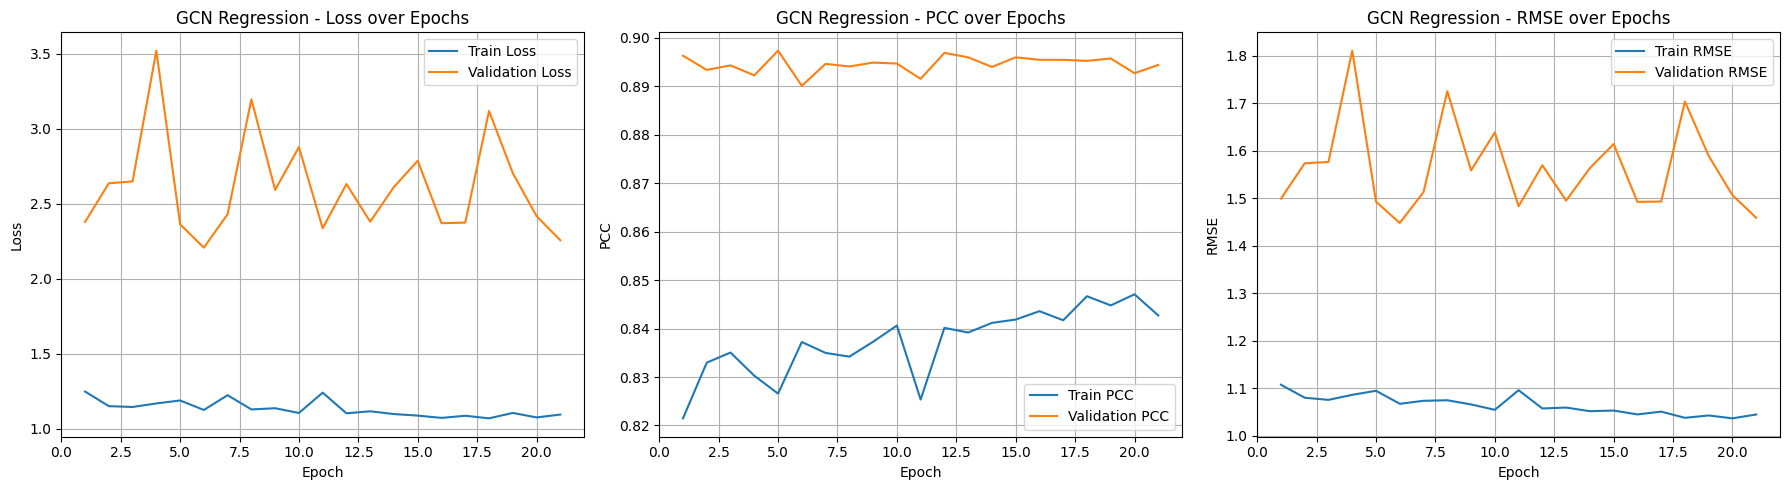


>>> FINAL AGGREGATED RESULTS FOR GCN Regression <<<
Total time taken: 37.82 seconds
  Test PCC: 0.7045 ± 0.0197
  Test RMSE: 1.5264 ± 0.0526

Running Experiment: GAT Regression (3 replicates)

--- Replicate 1/3 ---
Training GAT Regression with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GAT Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(59, 64, heads=4)
      (1): ELU(alpha=1.0)
      (2): GATConv(256, 64, heads=1)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)


Epoch 5/200
  Train - Loss: 2.6911, pcc: 0.5411, rmse: 1.6265
  Val   - Loss: 4.0834, pcc: 0.7996, rmse: 1.9734
Epoch 10/200
  Train - Loss: 2.0150, pcc: 0.6953, rmse: 1.3920
  Val   - Loss: 3.2975, pcc: 0.8095, rmse: 1.7822
Epoch 15/200
  Train - Loss: 1.5592, pcc: 0.7768, rmse: 1.2183
  Val   - Loss: 2.2897, pcc: 0.8581, rmse: 1.5026
Epoch 

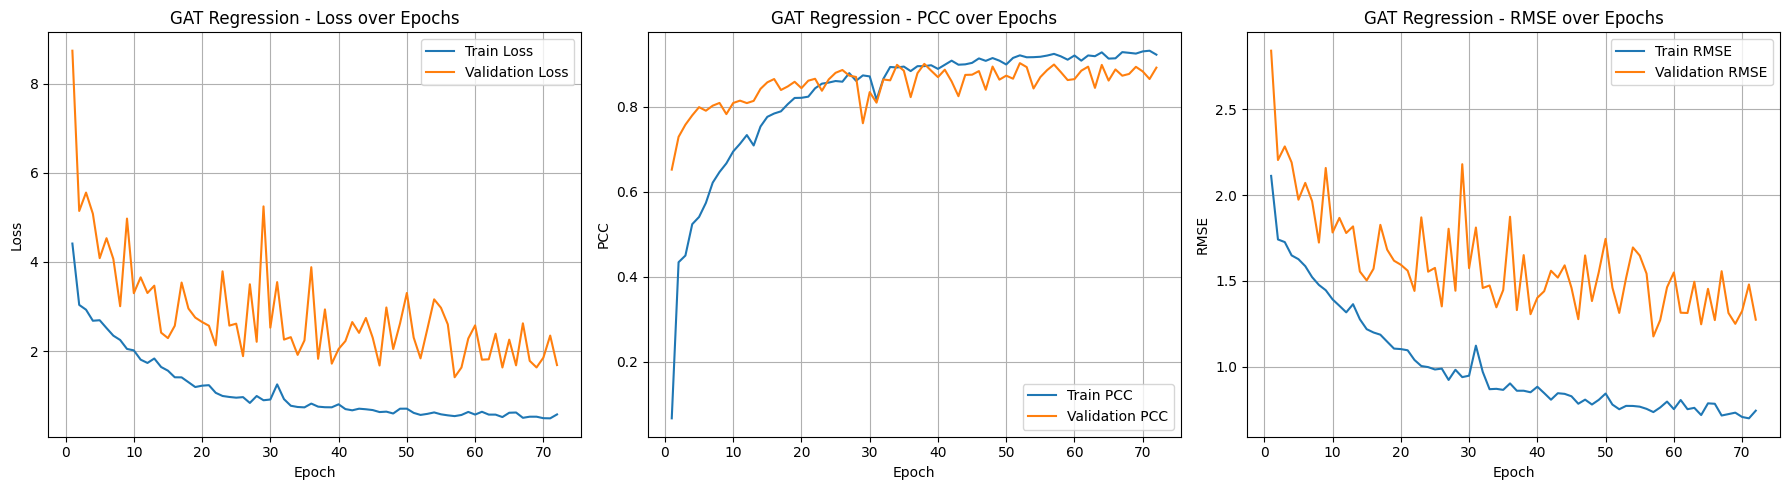


--- Replicate 2/3 ---
Training GAT Regression with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GAT Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(59, 64, heads=4)
      (1): ELU(alpha=1.0)
      (2): GATConv(256, 64, heads=1)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)


Epoch 5/200
  Train - Loss: 0.5324, pcc: 0.9243, rmse: 0.7378
  Val   - Loss: 2.3878, pcc: 0.8728, rmse: 1.4861
Epoch 10/200
  Train - Loss: 0.5341, pcc: 0.9253, rmse: 0.7332
  Val   - Loss: 1.8004, pcc: 0.8828, rmse: 1.3069
Epoch 15/200
  Train - Loss: 0.5561, pcc: 0.9217, rmse: 0.7500
  Val   - Loss: 1.9334, pcc: 0.8843, rmse: 1.3542
Epoch 20/200
  Train - Loss: 0.5455, pcc: 0.9232, rmse: 0.7432
  Val   - Loss: 1.7783, pcc: 0.8980, rmse: 1.2994
Early stopping triggered at epoch 24!
  Final Test Metrics: pcc: 0.7887, rmse: 1.3013


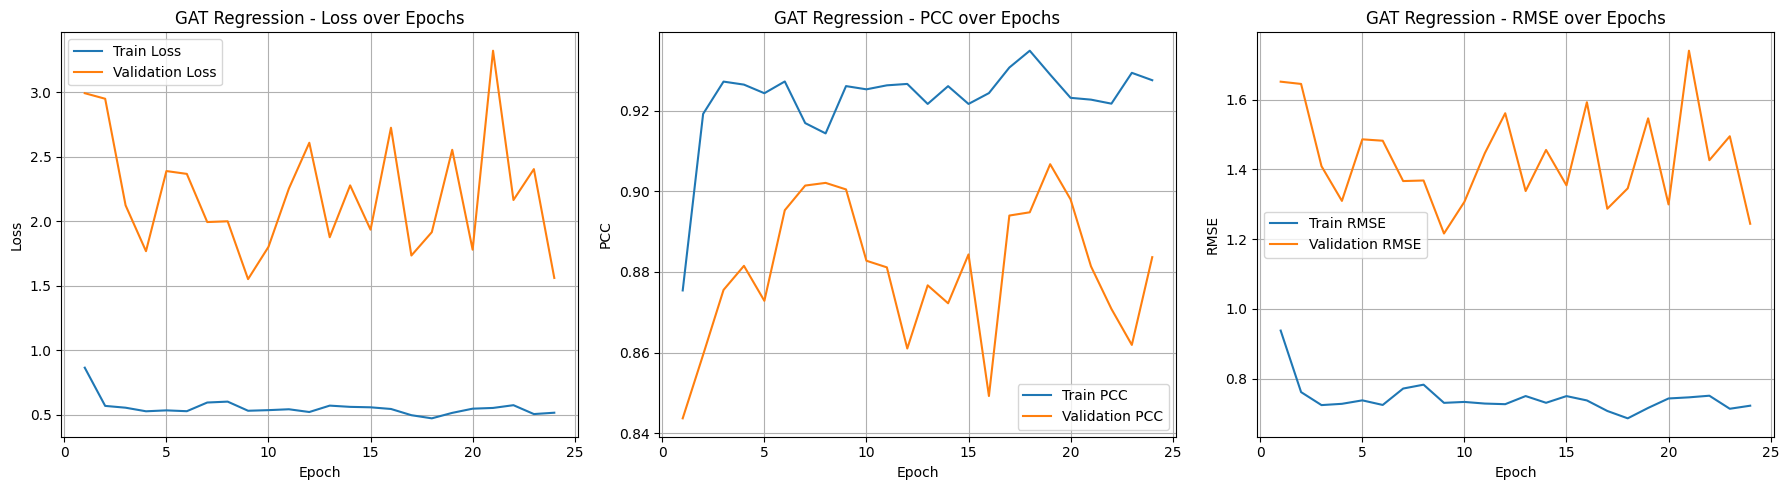


--- Replicate 3/3 ---
Training GAT Regression with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GAT Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(59, 64, heads=4)
      (1): ELU(alpha=1.0)
      (2): GATConv(256, 64, heads=1)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)


Epoch 5/200
  Train - Loss: 0.6573, pcc: 0.9070, rmse: 0.8150
  Val   - Loss: 2.5103, pcc: 0.8599, rmse: 1.5212
Epoch 10/200
  Train - Loss: 0.4800, pcc: 0.9329, rmse: 0.6968
  Val   - Loss: 2.0698, pcc: 0.8800, rmse: 1.4000
Epoch 15/200
  Train - Loss: 0.4890, pcc: 0.9334, rmse: 0.6938
  Val   - Loss: 2.3623, pcc: 0.8872, rmse: 1.4827
Early stopping triggered at epoch 19!
  Final Test Metrics: pcc: 0.7802, rmse: 1.3568


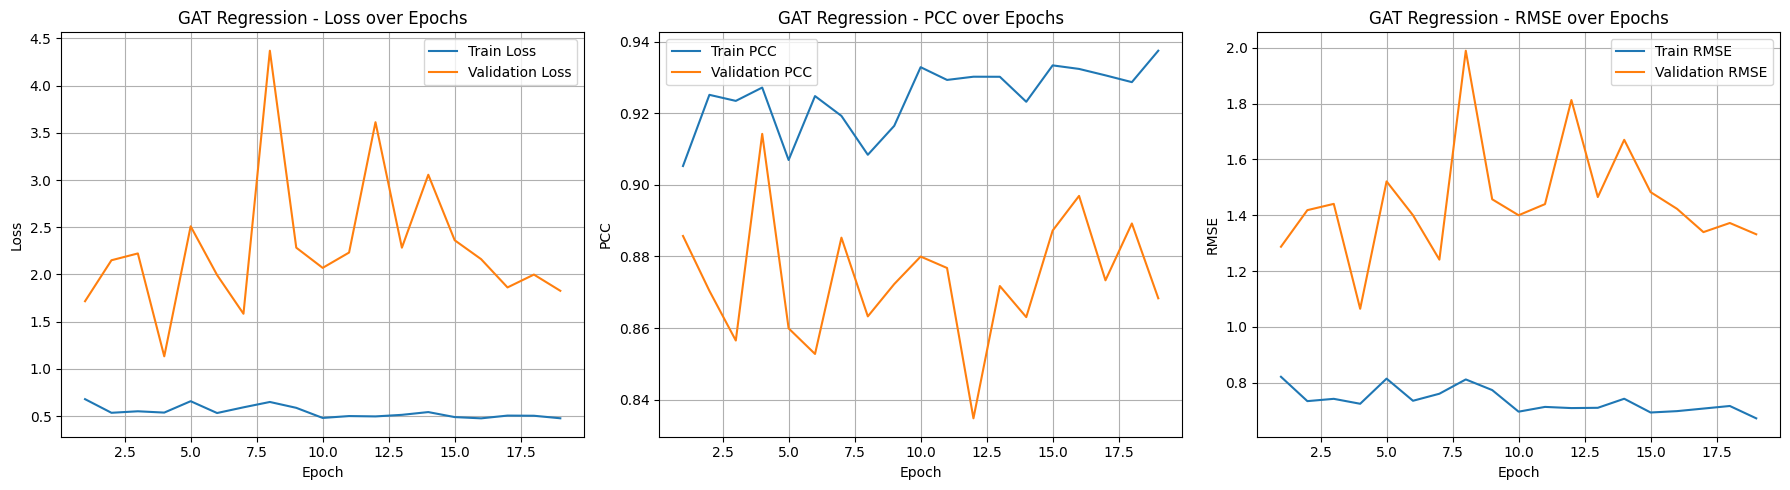


>>> FINAL AGGREGATED RESULTS FOR GAT Regression <<<
Total time taken: 53.28 seconds
  Test PCC: 0.7762 ± 0.0121
  Test RMSE: 1.3593 ± 0.0484


In [15]:
esol_max_vals = get_max_values(esol)


reg_batch_size = 32
reg_n_epochs = 200
reg_onehot_sizes=esol_max_vals[1:]

import sys
DEBUG_MODE = '--test' in sys.argv
if DEBUG_MODE:
    print("\n[WARNING] Running in FAST DEBUG MODE. Disabling large epochs and replicates.")
    reg_n_epochs = 1
    repeat_factor = 1
    # Shrink datasets
    esol_train_dataset = torch.utils.data.Subset(esol_train_dataset, range(min(10, len(esol_train_dataset))))
    esol_val_dataset = torch.utils.data.Subset(esol_val_dataset, range(min(5, len(esol_val_dataset))))
    esol_test_dataset = torch.utils.data.Subset(esol_test_dataset, range(min(5, len(esol_test_dataset))))

# Setup
hidden_features = 64
embedding_dim=32
# (reg_embedding removed because embeddings are constructed per-experiment)

# Total dimension: 32 (atomic) + sum of one-hot dimensions
# Add 1 to each size in esol_max_vals[1:] for one-hot encoding
# There are 9 features in the ESOL dataset
in_features = embedding_dim + sum([size + 1 for size in esol_max_vals[1:]])
print(f"in features: {in_features}")

# --- REGRESSION EXPERIMENTS (ESOL) ---
# TODO: Present results for the regression task and compare model types. This
# can be in the form of tables or graphs or however you see fit
reg_results = {}
reg_results["DeepSet"] = run_experiment(MolecularGraphRegression,
               {"embedding": torch.nn.Embedding(num_embeddings=esol_max_vals[0]+1, embedding_dim=embedding_dim),
                "net": DeepSet(in_features, hidden_features),
                "onehot_sizes": reg_onehot_sizes,
                "name": "DeepSet Regression"},
               esol_train_dataset, esol_val_dataset, esol_test_dataset, reg_batch_size, reg_n_epochs)

reg_results["GCN"] = run_experiment(MolecularGraphRegression,
               {"embedding": torch.nn.Embedding(num_embeddings=esol_max_vals[0]+1, embedding_dim=embedding_dim),
                "net": GCN(in_features, hidden_features),
                "onehot_sizes": reg_onehot_sizes,
                "name": "GCN Regression"},
               esol_train_dataset, esol_val_dataset, esol_test_dataset, reg_batch_size, reg_n_epochs)

reg_results["GAT"] = run_experiment(MolecularGraphRegression,
               {"embedding": torch.nn.Embedding(num_embeddings=esol_max_vals[0]+1, embedding_dim=embedding_dim),
                "net": GAT(in_features, hidden_features, heads=4),
                "onehot_sizes": reg_onehot_sizes,
                "name": "GAT Regression"},
               esol_train_dataset, esol_val_dataset, esol_test_dataset, reg_batch_size, reg_n_epochs)


Running Experiment: DeepSet Classification (3 replicates)

--- Replicate 1/3 ---
Training DeepSet Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=63, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)


Epoch 5/200
  Train - Loss: 0.4574, roc_auc: 0.7882
  Val   - Loss: 0.4004, roc_auc: 0.8394
Epoch 10/200
  Train - Loss: 0.4410, roc_auc: 0.8053
  Val   - Loss: 0.3847, roc_auc: 0.8632
Epoch 15/200
  Train - Loss: 0.4319, roc_auc: 0.8083
  Val   - Loss: 0.3688, roc_auc: 0.8740
Epoch 20/200
  Train - Loss: 0.4306, roc_auc: 0.8219
  Val   - Loss: 0.3549, roc_auc: 0.8827
Epoch 25/200
  Train - Loss: 0.4349, roc_auc: 0.8253
  Val   - Loss: 0.36

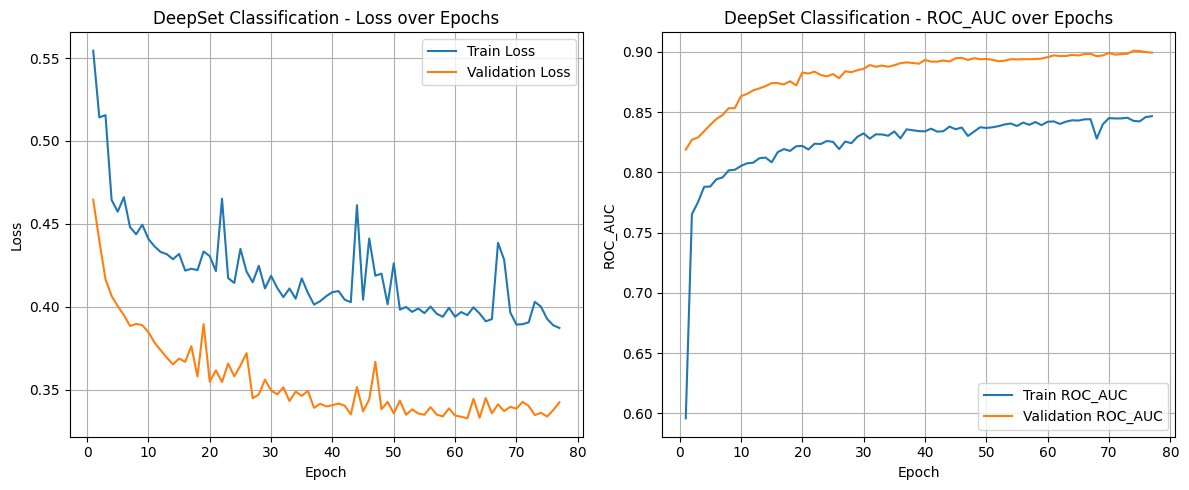


--- Replicate 2/3 ---
Training DeepSet Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=63, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)


Epoch 5/200
  Train - Loss: 0.3941, roc_auc: 0.8443
  Val   - Loss: 0.3346, roc_auc: 0.8974
Epoch 10/200
  Train - Loss: 0.3948, roc_auc: 0.8431
  Val   - Loss: 0.3311, roc_auc: 0.8993
Epoch 15/200
  Train - Loss: 0.3958, roc_auc: 0.8363
  Val   - Loss: 0.3330, roc_auc: 0.8940
Epoch 20/200
  Train - Loss: 0.4100, roc_auc: 0.8432
  Val   - Loss: 0.3346, roc_auc: 0.8996
Epoch 25/200
  Train - Loss: 0.3902, roc_auc: 0.8475
  Val   - Loss: 0.3470, roc_auc: 0.8990
Early stopping triggered at epoch 25!
 

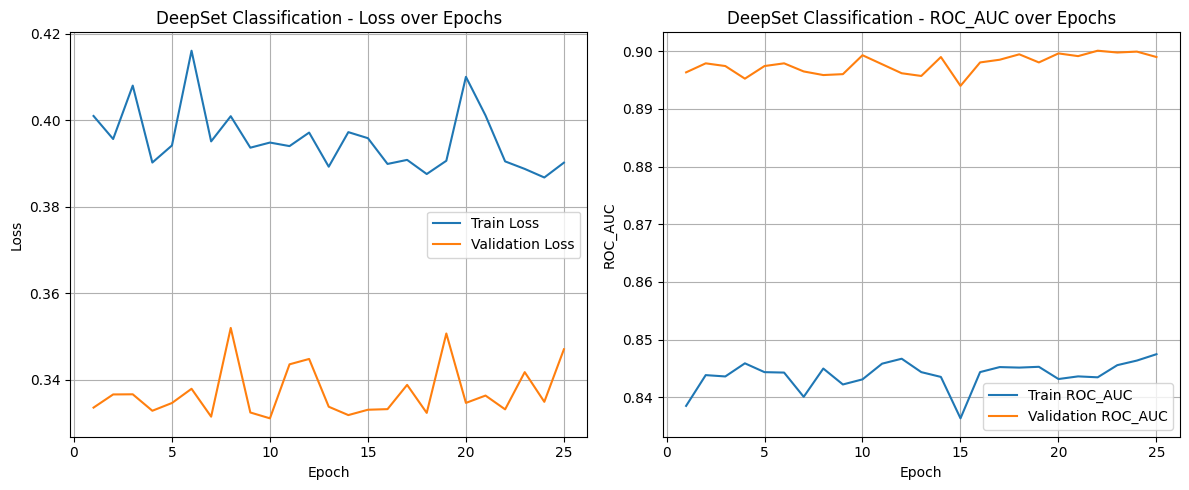


--- Replicate 3/3 ---
Training DeepSet Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=63, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)


Epoch 5/200
  Train - Loss: 0.3902, roc_auc: 0.8440
  Val   - Loss: 0.3317, roc_auc: 0.9001
Epoch 10/200
  Train - Loss: 0.3862, roc_auc: 0.8485
  Val   - Loss: 0.3358, roc_auc: 0.8992
Epoch 15/200
  Train - Loss: 0.3932, roc_auc: 0.8516
  Val   - Loss: 0.3315, roc_auc: 0.8996
Epoch 20/200
  Train - Loss: 0.3845, roc_auc: 0.8500
  Val   - Loss: 0.3310, roc_auc: 0.9026
Epoch 25/200
  Train - Loss: 0.4593, roc_auc: 0.8266
  Val   - Loss: 0.3459, roc_auc: 0.8968
Epoch 30/200
  Train - Loss: 0.3866, ro

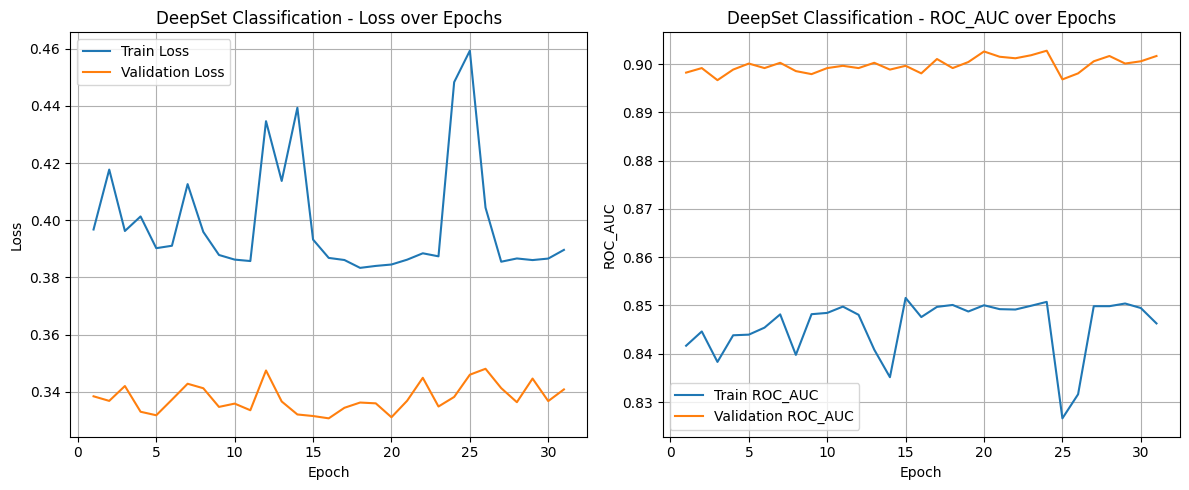


>>> FINAL AGGREGATED RESULTS FOR DeepSet Classification <<<
Total time taken: 49.36 seconds
  Test ROC_AUC: 0.6862 ± 0.0084

Running Experiment: GCN Classification (3 replicates)

--- Replicate 1/3 ---
Training GCN Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GCN Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(63, 64)
      (1): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)


Epoch 5/200
  Train - Loss: 0.4928, roc_auc: 0.7881
  Val   - Loss: 0.4139, roc_auc: 0.8421
Epoch 10/200
  Train - Loss: 0.4398, roc_auc: 0.8048
  Val   - Loss: 0.3811, roc_auc: 0.8671
Epoch 15/200
  Train - Loss: 0.4239, roc_auc: 0.8184
  Val   - Loss: 0.3669, roc_auc: 0.8752
Epoch 20/200
  Train - Loss: 0.4133, roc_auc: 0.8283
  Val   - Loss: 0.3783, roc_auc: 0.8790
Epoch 25/200
  Tr

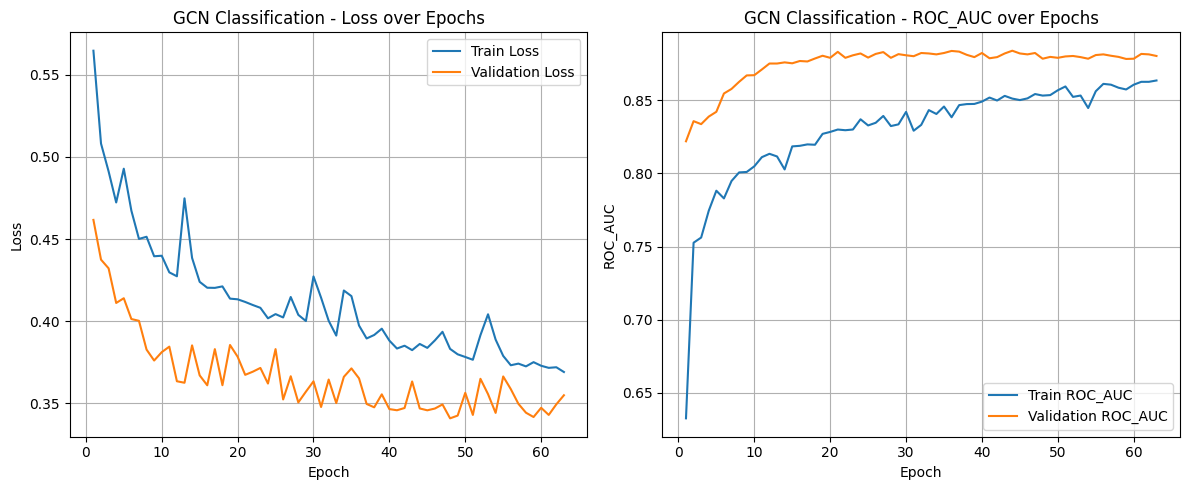


--- Replicate 2/3 ---
Training GCN Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GCN Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(63, 64)
      (1): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)


Epoch 5/200
  Train - Loss: 0.3805, roc_auc: 0.8555
  Val   - Loss: 0.3523, roc_auc: 0.8831
Epoch 10/200
  Train - Loss: 0.3716, roc_auc: 0.8622
  Val   - Loss: 0.3455, roc_auc: 0.8849
Epoch 15/200
  Train - Loss: 0.3685, roc_auc: 0.8632
  Val   - Loss: 0.3457, roc_auc: 0.8834
Epoch 20/200
  Train - Loss: 0.3681, roc_auc: 0.8680
  Val   - Loss: 0.3450, roc_auc: 0.8802
Epoch 25/200
  Train - Loss: 0.3686, roc_auc: 0.8690
  Val   - Loss: 0.3427, roc_auc: 0.8823
Epoch 30/200
  Train - Loss: 0.3771, roc_auc: 0.8555
  Val   - Loss: 0.3340, roc_auc: 0.8843
Epoch 35/20

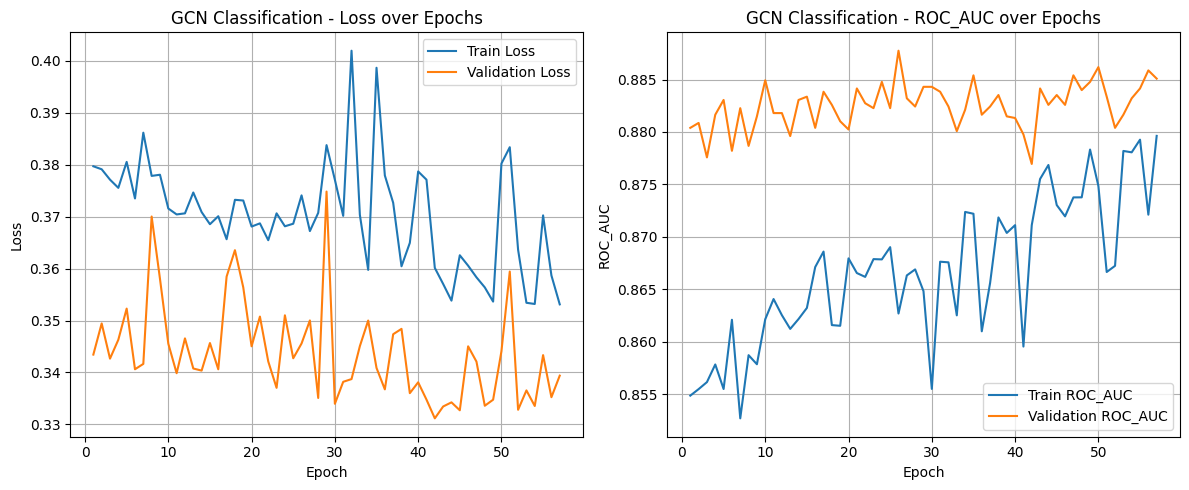


--- Replicate 3/3 ---
Training GCN Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GCN Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(63, 64)
      (1): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)


Epoch 5/200
  Train - Loss: 0.3561, roc_auc: 0.8744
  Val   - Loss: 0.3373, roc_auc: 0.8857
Epoch 10/200
  Train - Loss: 0.3697, roc_auc: 0.8747
  Val   - Loss: 0.3390, roc_auc: 0.8860
Epoch 15/200
  Train - Loss: 0.3646, roc_auc: 0.8715
  Val   - Loss: 0.3581, roc_auc: 0.8813
Epoch 20/200
  Train - Loss: 0.3570, roc_auc: 0.8778
  Val   - Loss: 0.3489, roc_auc: 0.8856
Epoch 25/200
  Train - Loss: 0.3772, roc_auc: 0.8811
  Val   - Loss: 0.3292, roc_auc: 0.8826
Epoch 30/200
  Train - Loss: 0.3609, roc_auc: 0.8809
  Val   - Loss: 0.3313, roc_auc: 0.8834
Epoch 35/20

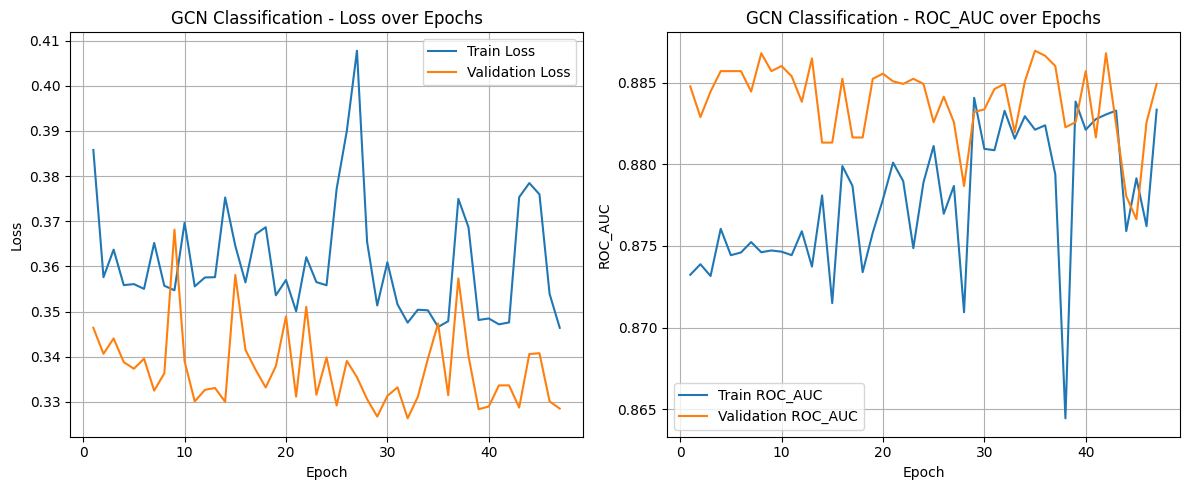


>>> FINAL AGGREGATED RESULTS FOR GCN Classification <<<
Total time taken: 79.89 seconds
  Test ROC_AUC: 0.7762 ± 0.0191

Running Experiment: GAT Classification (3 replicates)

--- Replicate 1/3 ---
Training GAT Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GAT Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(63, 64, heads=4)
      (1): ELU(alpha=1.0)
      (2): GATConv(256, 64, heads=1)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)


Epoch 5/200
  Train - Loss: 0.4128, roc_auc: 0.8147
  Val   - Loss: 0.3618, roc_auc: 0.8735
Epoch 10/200
  Train - Loss: 0.3966, roc_auc: 0.8383
  Val   - Loss: 0.3560, roc_auc: 0.8743
Epoch 15/200
  Train - Loss: 0.3728, roc_auc: 0.8513
  Val   - Loss: 0.3760, roc_auc: 0.8834
Epoch 20/200
  Train - L

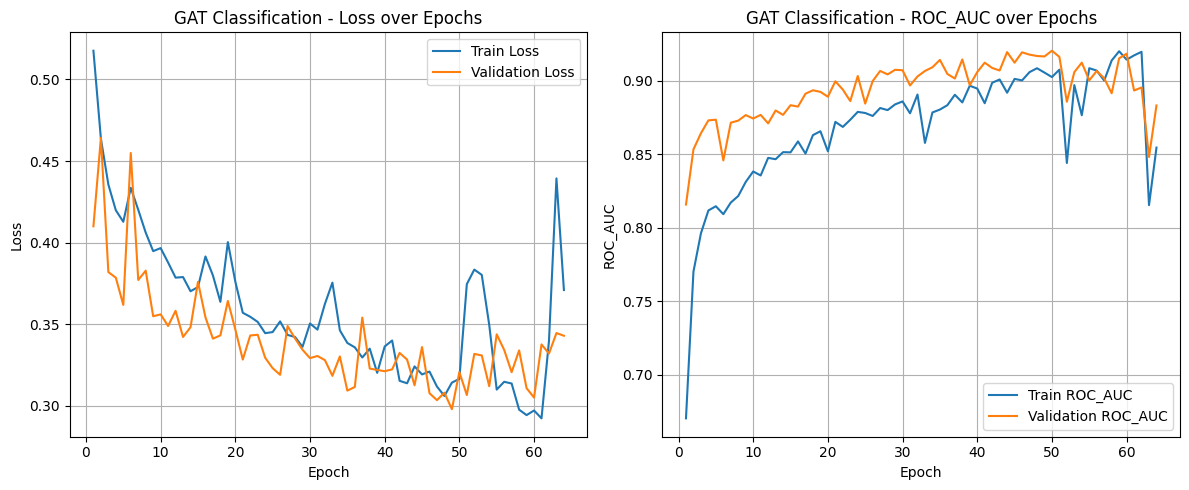


--- Replicate 2/3 ---
Training GAT Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GAT Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(63, 64, heads=4)
      (1): ELU(alpha=1.0)
      (2): GATConv(256, 64, heads=1)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)


Epoch 5/200
  Train - Loss: 0.3071, roc_auc: 0.9104
  Val   - Loss: 0.3288, roc_auc: 0.9165
Epoch 10/200
  Train - Loss: 0.2871, roc_auc: 0.9198
  Val   - Loss: 0.3339, roc_auc: 0.8987
Epoch 15/200
  Train - Loss: 0.2800, roc_auc: 0.9234
  Val   - Loss: 0.3111, roc_auc: 0.9028
Epoch 20/200
  Train - Loss: 0.2838, roc_auc: 0.9222
  Val   - Loss: 0.3254, roc_auc: 0.8923
Early stopping triggered at epoch 21!
  Final Test Metrics: roc_auc: 0.8305


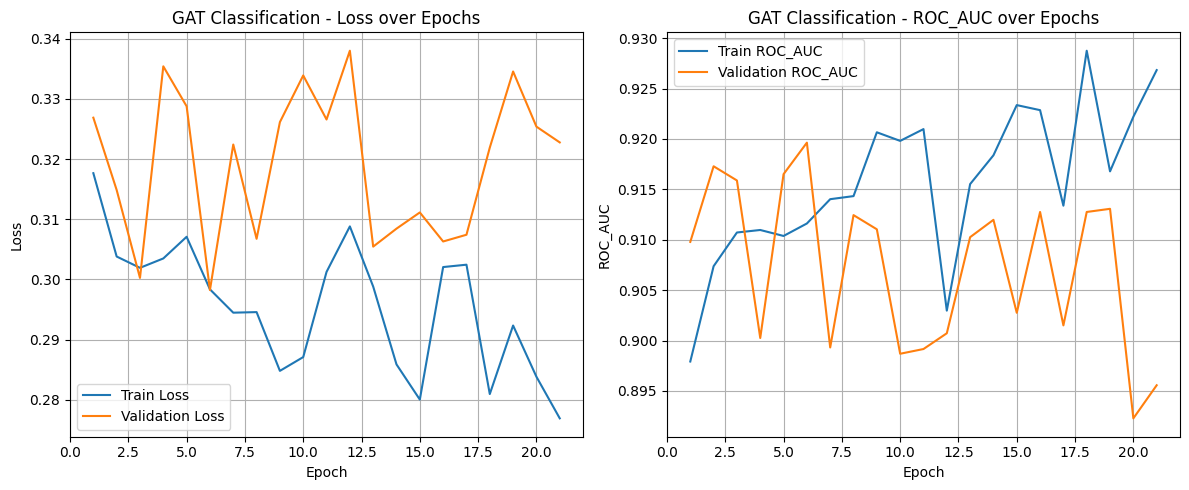


--- Replicate 3/3 ---
Training GAT Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GAT Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(63, 64, heads=4)
      (1): ELU(alpha=1.0)
      (2): GATConv(256, 64, heads=1)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)


Epoch 5/200
  Train - Loss: 0.2914, roc_auc: 0.9152
  Val   - Loss: 0.3307, roc_auc: 0.9007
Epoch 10/200
  Train - Loss: 0.2789, roc_auc: 0.9246
  Val   - Loss: 0.3153, roc_auc: 0.9118
Epoch 15/200
  Train - Loss: 0.2804, roc_auc: 0.9263
  Val   - Loss: 0.3396, roc_auc: 0.8857
Epoch 20/200
  Train - Loss: 0.2795, roc_auc: 0.9271
  Val   - Loss: 0.3535, roc_auc: 0.8690
Epoch 25/200
  Train - Loss: 0.2722, roc_auc: 0.9329
  Val   - Loss: 0.3354, roc_auc: 0.8967
Epoch 30/200
 

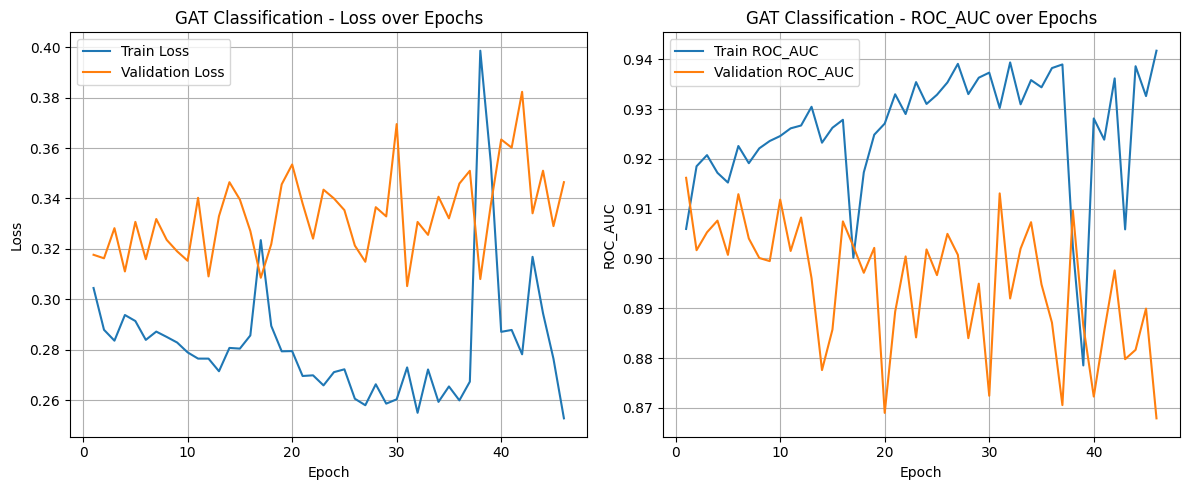


>>> FINAL AGGREGATED RESULTS FOR GAT Classification <<<
Total time taken: 157.68 seconds
  Test ROC_AUC: 0.8193 ± 0.0098


In [12]:
# Setup for BBBP (Classification)
# There are 9 features in the BBBP dataset
bbbp_max_vals = get_max_values(bbbp)
class_batch_size = 32
class_n_epochs = 200
class_onehot_sizes = bbbp_max_vals[1:]
in_features_classification = embedding_dim + sum([size + 1 for size in bbbp_max_vals[1:]])

if DEBUG_MODE:
    class_n_epochs = 1
    bbbp_train_dataset = torch.utils.data.Subset(bbbp_train_dataset, range(min(10, len(bbbp_train_dataset))))
    bbbp_val_dataset = torch.utils.data.Subset(bbbp_val_dataset, range(min(5, len(bbbp_val_dataset))))
    bbbp_test_dataset = torch.utils.data.Subset(bbbp_test_dataset, range(min(5, len(bbbp_test_dataset))))

# --- CLASSIFICATION EXPERIMENTS (BBBP) ---
cls_results = {}
cls_results["DeepSet"] = run_experiment(MolecularGraphClassification,
               {"embedding": torch.nn.Embedding(num_embeddings=bbbp_max_vals[0]+1, embedding_dim=embedding_dim),
                "net": DeepSet(in_features_classification, hidden_features),
                "onehot_sizes": class_onehot_sizes,
                "name": "DeepSet Classification"},
               bbbp_train_dataset, bbbp_val_dataset, bbbp_test_dataset, class_batch_size, class_n_epochs)

cls_results["GCN"] = run_experiment(MolecularGraphClassification,
               {"embedding": torch.nn.Embedding(num_embeddings=bbbp_max_vals[0]+1, embedding_dim=embedding_dim),
                "net": GCN(in_features_classification, hidden_features),
                "onehot_sizes": class_onehot_sizes,
                "name": "GCN Classification"},
               bbbp_train_dataset, bbbp_val_dataset, bbbp_test_dataset, class_batch_size, class_n_epochs)

cls_results["GAT"] = run_experiment(MolecularGraphClassification,
               {"embedding": torch.nn.Embedding(num_embeddings=bbbp_max_vals[0]+1, embedding_dim=embedding_dim),

                "net": GAT(in_features_classification, hidden_features, heads=4),
                "onehot_sizes": class_onehot_sizes,
                "name": "GAT Classification"},
               bbbp_train_dataset, bbbp_val_dataset, bbbp_test_dataset, class_batch_size, class_n_epochs)


Generating comparison plots...

FINAL RESULTS FOR REGRESSION

Model: DeepSet
  Test RMSE: 1.3630 ± 0.0221
  Test PCC: 0.7639 ± 0.0090

Model: GCN
  Test RMSE: 1.5264 ± 0.0526
  Test PCC: 0.7045 ± 0.0197

Model: GAT
  Test RMSE: 1.3593 ± 0.0484
  Test PCC: 0.7762 ± 0.0121


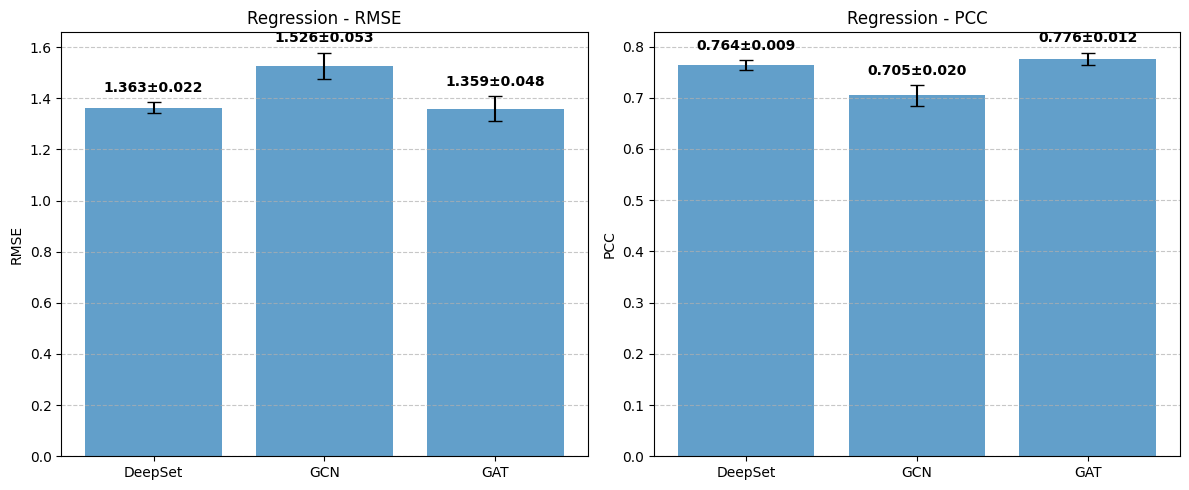


FINAL RESULTS FOR CLASSIFICATION

Model: DeepSet
  Test ROC_AUC: 0.6862 ± 0.0084

Model: GCN
  Test ROC_AUC: 0.7762 ± 0.0191

Model: GAT
  Test ROC_AUC: 0.8193 ± 0.0098


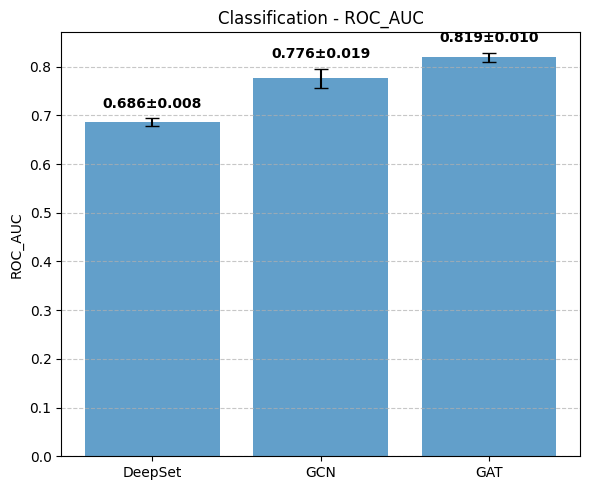


All experiments completed in 2839.62 seconds.


In [17]:

def plot_final_comparison(results_dict, task_name, metrics):
    print(f"\n{'='*50}\nFINAL RESULTS FOR {task_name.upper()}\n{'='*50}")
    for model_name, metrics_data in results_dict.items():
        print(f"\nModel: {model_name}")
        for metric in metrics:
            mean, std = metrics_data[metric]
            print(f"  Test {metric.upper()}: {mean:.4f} ± {std:.4f}")

    num_metrics = len(metrics)
    fig, axes = plt.subplots(1, num_metrics, figsize=(6 * num_metrics, 5))
    if num_metrics == 1:
        axes = [axes]

    models = list(results_dict.keys())

    for i, metric in enumerate(metrics):
        means = [results_dict[m][metric][0] for m in models]
        stds = [results_dict[m][metric][1] for m in models]

        bars = axes[i].bar(models, means, yerr=stds, capsize=5, alpha=0.7)
        axes[i].set_title(f'{task_name} - {metric.upper()}')
        axes[i].set_ylabel(metric.upper())
        axes[i].grid(axis='y', linestyle='--', alpha=0.7)

        # Add numeric labels on top of the bars for easy reading
        for bar, mean, std in zip(bars, means, stds):
            yval = bar.get_height()
            # Position the text slightly above the error bar
            axes[i].text(bar.get_x() + bar.get_width()/2, yval + std + (0.02 * abs(yval)),
                         f'{mean:.3f}±{std:.3f}',
                         ha='center', va='bottom', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.savefig(f"{task_name.lower()}_comparison.png")
    plt.show()

print("\nGenerating comparison plots...")
plot_final_comparison(reg_results, "Regression", ["rmse", "pcc"])
plot_final_comparison(cls_results, "Classification", ["roc_auc"])

overall_end_time = time.time()

print(f"\nAll experiments completed in {overall_end_time - overall_start_time:.2f} seconds.")

Here's a brief outline of what has been done:

1.  **Installed necessary libraries:** Installed `torch`, `torch_geometric`, `rdkit`, `torcheval`, and `matplotlib`, and cloned a GitHub repository containing relevant code.
2.  **Set up the device:** Determined whether to use CUDA, MPS, or CPU for training.
3.  **Loaded and filtered datasets:** Loaded the ESOL and BBBP datasets using `torch_geometric.datasets.MoleculeNet`. A function `filter_small_graphs` was implemented and used to remove molecules with fewer than 2 nodes from both datasets.
4.  **Split datasets:** Split the filtered ESOL and BBBP datasets into training and validation sets using a scaffold split.
5. **Defined Model Architectures:** Created classes for base molecular graph networks (`MolecularGraphNet`), and specific implementations for classification (`MolecularGraphClassification`) and regression (`MolecularGraphRegression`). We also defined the architectures for different graph neural network layers: `DeepSet`, `GCN`, and `GAT`. As our baseline, we implemented a DeepSet architecture for both regression and classification that ignores graph structure. We tried different batch sizes to improve performance while also preventing issues during training (such as Pearson correlation not being defined). This model serves as an important baseline to determine whether graph structure provides meaningful signal beyond node features alone. For our spatial models, we implemented GCN based on Kipf & Welling [2], using the layer-wise propagation rule:
   
   $H^{(l+1)} = \sigma(\tilde{D}^{-1/2} \tilde{A} \tilde{D}^{-1/2} H^{(l)} W^{(l)})$

   where $\tilde{A} = A + I_N$ is the adjacency matrix with self-connections and $\tilde{D}$ is the corresponding degree matrix. This formulation provides an efficient first-order approximation of spectral graph convolutions.

6.  **Defined Training and Plotting Functions:** Implemented functions for plotting training results (`plot_results`) and training the models (`train`), including logging with Weights & Biases. A helper function `get_max_values` was created to determine feature dimensions for embedding.
7.  **Instantiated and Trained Models:** Initialized and trained instances of `MolecularGraphRegression` (using DeepSet, GCN, and GAT) on the ESOL dataset and `MolecularGraphClassification` (again using DeepSet, GCN and GAT) on the BBBP dataset.

## Model Comparison

Below is the comparison of the different models on the ESOL (Regression) and BBBP (Classification) tasks:

1. **DeepSet (Baseline)**: This model applies a per-node MLP and then pools the results globally. It does not use the graph structure (edges) at all. It serves as a baseline to see how much can be learned purely from atomic properties without structural context.
2. **GCN (Graph Convolutional Network)**: GCN aggregates features from immediate neighbors using an isotropic weighting scheme based on node degrees. It can capture local structural motifs but struggles to distinguish between neighbors of different importance.
3. **GAT (Graph Attention Network)**: GAT uses multi-head attention to learn dynamic weights for different neighbors. It can attend to specific chemical bonds or substructures that are most relevant to the target property.

**Discussion**:
GCN and GAT are expected to outperform the DeepSet baseline because molecular properties (like solubility or blood-brain barrier permeability) heavily depend on the structural arrangement of atoms (e.g., rings, functional groups), not just the sheer presence of certain atoms. Between GCN and GAT, GAT often achieves better performance because its attention mechanism allows it to focus on critical structural features rather than treating all bonds equally.
